In [1]:
# ===== 1.1 CONFIG & IMPORTS =====
#%pip install -q spectral

import os, glob, time, shutil, json, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

# Colab: META="/content/description-2.csv", WORK="/content", CUBE_DIR="/content/cubes"
META = next(p for p in glob.glob("/kaggle/input/**/description-2.csv", recursive=True))   # check the real path in the Input panel
WORK     = "/kaggle/working"    # small outputs, kept after the session
CUBE_DIR = "/tmp/cubes"         # raw images, large and temporary
API      = "https://entrepot.recherche.data.gouv.fr/api"
DOI      = "doi:10.57745/WW7TY7"
SEED     = 42

for d in [WORK, CUBE_DIR, f"{WORK}/spectra_v2", f"{WORK}/masks", f"{WORK}/qc"]:
    os.makedirs(d, exist_ok=True)
os.chdir(WORK)

In [2]:
# ===== 1.2 METADATA -> COHORT (healthy vs FD) -> TABLE 1 =====
df = pd.read_csv(META, sep=";", encoding="cp1252")   # utf-8 fails on the "œ" in Loin de l'œil
print(df.shape)
df["variety"] = df["variety"].str.replace(r"^Loin.*", "Loin de l'Oeil", regex=True)

sym = df["symptom"].str.lower()
cohort = df[sym.str.startswith("flavescence") | (sym == "healthy")].copy()   # startswith avoids the accent in "dorée"
cohort["label"] = cohort["symptom"].str.lower().str.startswith("flavescence").astype(int)   # 1 = FD, 0 = healthy

table1 = pd.crosstab(cohort["variety"], cohort["label"])
table1.columns = ["Healthy", "FD"]     # raises if a class is missing
table1["Total"] = table1.sum(axis=1)
table1.loc["Total"] = table1.sum()
display(table1)                        # expect 40 / 80 / 120

assert len(cohort) == 120, "cohort size changed: re-check symptom labels"
assert cohort[["Chl", "Flav", "NBI"]].notna().all().all(), "missing Dualex values"
cohort.to_csv(f"{WORK}/cohort.csv", index=False, encoding="utf-8")

(204, 10)


,Healthy,FD,Total
variety,,,
Chardonnay,11,12,23
Colombard,5,10,15
Duras,3,9,12
Fer,5,10,15
Gamay,11,19,30
Loin de l'Oeil,0,10,10
Mauzac,5,10,15
Total,40,80,120


In [3]:
# ===== 1.3 LIST DATASET FILES -> SELECT COHORT results/ FILES =====
rows, seen, offset, page = [], set(), 0, 0
while page < 20:                       # cap: a server that ignores offset can't loop forever
    r = requests.get(f"{API}/datasets/:persistentId/versions/:latest/files",
                     params={"persistentId": DOI, "limit": 200, "offset": offset}, timeout=60)
    r.raise_for_status()
    data = r.json()["data"]
    new = 0
    for f in data:
        d = f["dataFile"]
        if d["id"] in seen:
            continue
        seen.add(d["id"]); new += 1
        rows.append({"id": d["id"], "dir": f.get("directoryLabel", ""),
                     "name": f["label"], "size": d.get("filesize", 0)})
    page += 1
    print(f"page {page}: got {len(data)}, new {new}, total {len(rows)}")
    if new == 0 or len(data) == 0:     # new == 0 after page 1 means the server ignores offset
        break
    offset += 200

files = pd.DataFrame(rows)
files["dir"] = files["dir"].fillna("")
files["leaf"] = files["dir"].str.extract(r"(\d{4}-\d{2}-\d{2}_\d{3})")[0]   # NaN for files outside leaf folders
files.to_csv(f"{WORK}/file_list.csv", index=False)

sel = files[files["leaf"].isin(cohort["directoryName"]) & files["dir"].str.contains("results")]
print(f"all files: {len(files)} | {files['size'].sum()/1e9:.1f} GB")
print(f"selected: {len(sel)} files | {sel['size'].sum()/1e9:.1f} GB | leaves covered: {sel['leaf'].nunique()} (expect 120)")
print(sel["name"].str.split(".").str[-1].value_counts())   # if selected is 0, check the folder paths in files["dir"]

page 1: got 2889, new 2889, total 2889
page 2: got 2889, new 0, total 2889
all files: 2889 | 66.5 GB
selected: 720 files | 26.2 GB | leaves covered: 120 (expect 120)
name
png    480
dat    120
hdr    120
Name: count, dtype: int64


In [4]:
%pip install -q spectral
import spectral
print(spectral.__version__)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Note: you may need to restart the kernel to use updated packages.
0.26


REFLECTANCE_2020-09-10_003.hdr | shape: (512, 512, 204) | wavelengths: 397.3 - 1003.6 nm
[('REFLECTANCE_2020-09-10_003.dat', 213.9), ('REFLECTANCE_2020-09-10_003.hdr', 0.0), ('REFLECTANCE_2020-09-10_003.png', 0.3), ('RGBBACKGROUND_2020-09-10_003.png', 0.7), ('RGBSCENE_2020-09-10_003.png', 1.9), ('RGBVIEWFINDER_2020-09-10_003.png', 1.4)]
reflectance range (subsampled): 0.005 1.141 | NaN fraction: 0.0


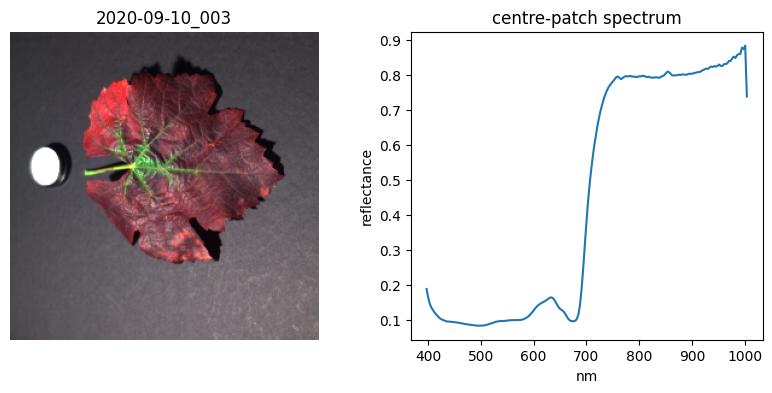

In [5]:
# ===== 1.4 SHARED HELPERS + INSPECT ONE LEAF =====
import spectral.io.envi as envi

def fetch(file_id, path, expected, tries=3):
    """Download one file; skip if it already exists with the right size."""
    if os.path.exists(path) and os.path.getsize(path) == expected:
        return True
    for _ in range(tries):
        try:
            with requests.get(f"{API}/access/datafile/{file_id}", stream=True, timeout=120) as r:
                r.raise_for_status()
                with open(path, "wb") as fh:
                    for chunk in r.iter_content(1 << 20):
                        fh.write(chunk)
            if os.path.getsize(path) == expected:
                return True
        except Exception as e:
            print("retry:", path, e); time.sleep(3)
    return False

def download_leaf(leaf):
    os.makedirs(f"{CUBE_DIR}/{leaf}", exist_ok=True)
    return all(fetch(f["id"], f"{CUBE_DIR}/{leaf}/{f['name']}", f["size"])
               for _, f in sel[sel["leaf"] == leaf].iterrows())

def load_cube(leaf):
    """Returns (cube [rows, cols, bands], wavelengths in nm, header name), or (None, None, None)."""
    hdrs = sorted(glob.glob(f"{CUBE_DIR}/{leaf}/*.hdr"))
    pick = [h for h in hdrs if "reflectance" in os.path.basename(h).lower()] or hdrs   # prefer the reflectance cube
    if not pick:
        return None, None, None
    img = envi.open(pick[0])
    return img.open_memmap(), np.array(img.bands.centers, dtype=float), os.path.basename(pick[0])

def rgb_preview(cube, wl):
    """Half-resolution RGB (650/550/470 nm) for visual checks."""
    b = lambda nm: int(np.argmin(np.abs(wl - nm)))
    rgb = np.stack([cube[::2, ::2, b(650)], cube[::2, ::2, b(550)], cube[::2, ::2, b(470)]], axis=-1).astype(float)
    return np.clip(rgb / np.percentile(rgb, 99), 0, 1)

# --- inspect one leaf: header, wavelengths, file sizes, picture, spectrum ---
leaf = cohort["directoryName"].iloc[0]
assert download_leaf(leaf), "download failed"
cube, wl, hdr = load_cube(leaf)
print(hdr, "| shape:", cube.shape, "| wavelengths:", wl.min().round(1), "-", wl.max().round(1), "nm")
print([(os.path.basename(p), round(os.path.getsize(p) / 1e6, 1)) for p in sorted(glob.glob(f"{CUBE_DIR}/{leaf}/*"))])
sub = np.asarray(cube[::16, ::16, :], dtype=float)
print("reflectance range (subsampled):", np.nanmin(sub).round(3), np.nanmax(sub).round(3), "| NaN fraction:", np.isnan(sub).mean())

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(rgb_preview(cube, wl)); ax[0].axis("off"); ax[0].set_title(leaf)
ax[1].plot(wl, np.asarray(cube[200:312, 200:312, :], dtype=float).reshape(-1, len(wl)).mean(0))
ax[1].set_xlabel("nm"); ax[1].set_ylabel("reflectance"); ax[1].set_title("centre-patch spectrum")
plt.show()

phase 2 (Segmentation and spectral extraction)

In [6]:
# ===== 2.1 LEAF MASK FUNCTIONS =====
from scipy import ndimage as ndi
from skimage.filters import threshold_otsu
from skimage.morphology import disk

RED_NM, NIR_NM = 670, 800     # nearest real bands are used; identical for every leaf

def band_mean(cube, wl, nm, half=2):
    i = int(np.argmin(np.abs(wl - nm)))
    return np.asarray(cube[:, :, max(i - half, 0): i + half + 1], dtype=np.float32).mean(axis=2)

def make_mask(cube, wl):
    """NDVI -> Otsu -> open/close -> largest region -> fill holes -> erode edge.
    Returns (mask, ndvi, otsu threshold, number of regions before keeping the largest)."""
    red, nir = band_mean(cube, wl, RED_NM), band_mean(cube, wl, NIR_NM)
    ndvi = np.nan_to_num((nir - red) / (nir + red + 1e-6), nan=0.0, posinf=0.0, neginf=0.0)
    t = threshold_otsu(ndvi)
    m = ndvi > t
    m = ndi.binary_opening(m, structure=disk(3))      # remove specks
    m = ndi.binary_closing(m, structure=disk(5))      # close small gaps
    lab, n = ndi.label(m)
    if n == 0:
        return m, ndvi, t, 0
    sizes = np.bincount(lab.ravel()); sizes[0] = 0
    m = ndi.binary_fill_holes(lab == sizes.argmax())  # keep only the largest region (the leaf)
    m = ndi.binary_erosion(m, structure=disk(3))      # drop mixed leaf/background edge pixels
    return m, ndvi, t, n

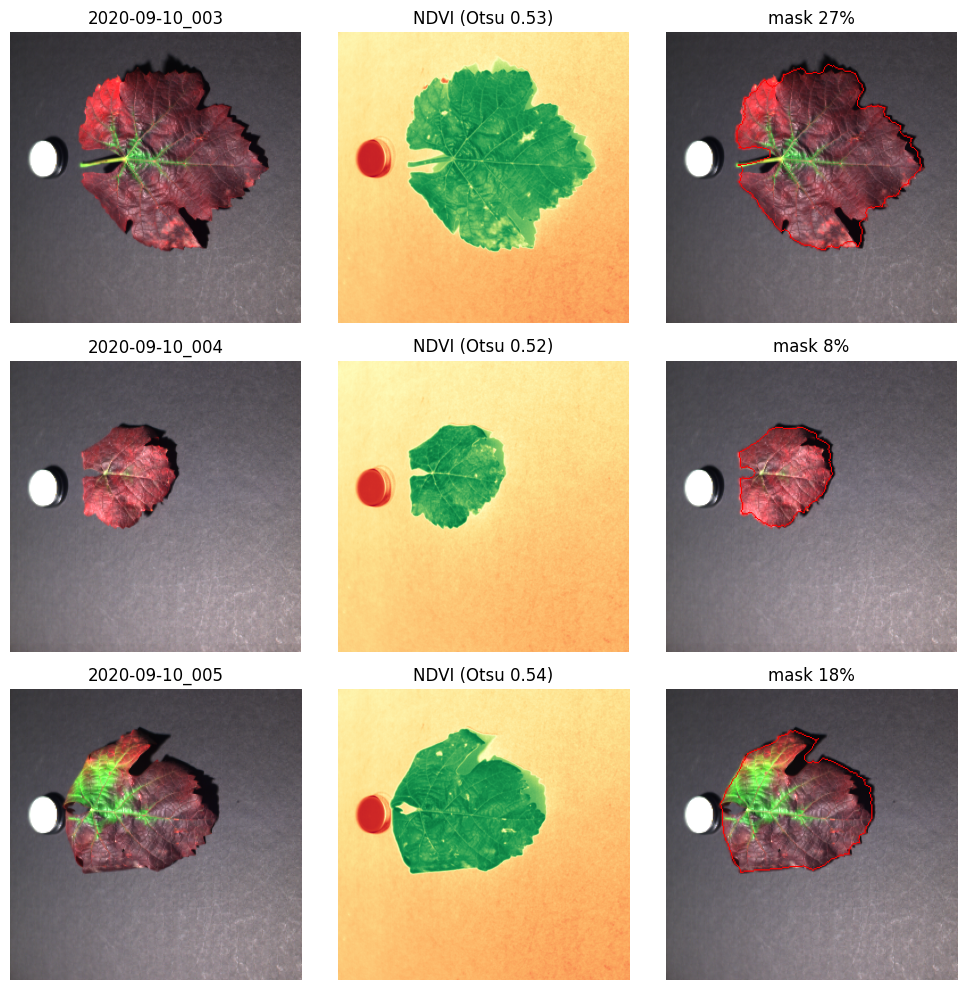

red band: 669.8 nm | NIR band: 798.8 nm


In [7]:
# ===== 2.2 MASK TEST ON 3 LEAVES (look before the full run) =====
test_leaves = cohort["directoryName"].iloc[:3].tolist()
fig, ax = plt.subplots(3, 3, figsize=(10, 10))
for r, leaf in enumerate(test_leaves):
    assert download_leaf(leaf), f"download failed: {leaf}"
    cube, wl, _ = load_cube(leaf)
    m, ndvi, t, _ = make_mask(cube, wl)
    rgb = rgb_preview(cube, wl)
    over = rgb.copy(); over[(m ^ ndi.binary_erosion(m, iterations=2))[::2, ::2]] = [1, 0, 0]
    ax[r, 0].imshow(rgb); ax[r, 1].imshow(ndvi, cmap="RdYlGn"); ax[r, 2].imshow(over)
    ax[r, 0].set_title(leaf); ax[r, 1].set_title(f"NDVI (Otsu {t:.2f})"); ax[r, 2].set_title(f"mask {m.mean():.0%}")
    for a in ax[r]: a.axis("off")
plt.tight_layout(); plt.show()
print("red band:", wl[np.argmin(np.abs(wl - RED_NM))].round(1), "nm | NIR band:", wl[np.argmin(np.abs(wl - NIR_NM))].round(1), "nm")

In [8]:
# ===== 2.3 MAIN LOOP: download -> mask -> mean spectrum -> QC picture =====
FREE_MIN_GB = 15       # delete a leaf's raw files only when free disk drops below this
PROCESS_LIMIT = None   # set e.g. 5 to test first, then None for the full run

todo = [l for l in cohort["directoryName"] if not os.path.exists(f"{WORK}/spectra_v2/{l}.npz")]
if PROCESS_LIMIT:
    todo = todo[:PROCESS_LIMIT]
print(len(todo), "leaves to process | free disk GB:", round(shutil.disk_usage(CUBE_DIR).free / 1e9))
failed, t0 = [], time.time()

for i, leaf in enumerate(todo, 1):
    try:
        if not download_leaf(leaf):
            failed.append((leaf, "download")); continue
        cube, wl, hdr = load_cube(leaf)
        if cube is None:
            failed.append((leaf, "no header")); continue

        m, ndvi, t, ncomp = make_mask(cube, wl)
        px = np.asarray(cube[m], dtype=np.float64)      # (leaf pixels, bands)
        good = np.isfinite(px).all(axis=1)
        spec = px[good].mean(axis=0)                    # Eq. 4: mean over valid leaf pixels

        # spectra file is written last: it marks the leaf as done, so a crash earlier means a retry
        np.savez_compressed(f"{WORK}/masks/{leaf}.npz", m=m)
        rgb = rgb_preview(cube, wl)
        rgb[(m ^ ndi.binary_erosion(m, iterations=2))[::2, ::2]] = [1, 0, 0]
        plt.imsave(f"{WORK}/qc/{leaf}.png", rgb)
        np.savez(f"{WORK}/spectra_v2/{leaf}.npz", spec=spec, wl=wl, n_px=int(good.sum()),
                 mask_frac=float(m.mean()), otsu_t=float(t), ncomp=int(ncomp), nonfinite=int((~good).sum()))
        del cube

        free = shutil.disk_usage(CUBE_DIR).free / 1e9
        if free < FREE_MIN_GB:
            shutil.rmtree(f"{CUBE_DIR}/{leaf}", ignore_errors=True)
        print(f"{i}/{len(todo)} {leaf} | mask {m.mean():.0%} | free {free:.0f} GB | {time.time()-t0:.0f}s")
    except Exception as e:
        failed.append((leaf, repr(e))); print("error", leaf, repr(e))

print("failed:", failed)

120 leaves to process | free disk GB: 1038
1/120 2020-09-10_003 | mask 27% | free 1038 GB | 0s
2/120 2020-09-10_004 | mask 8% | free 1038 GB | 1s
3/120 2020-09-10_005 | mask 18% | free 1038 GB | 1s
4/120 2020-09-10_006 | mask 11% | free 1037 GB | 18s
5/120 2020-09-10_007 | mask 15% | free 1037 GB | 38s
6/120 2020-09-10_008 | mask 10% | free 1037 GB | 55s
7/120 2020-09-10_009 | mask 8% | free 1037 GB | 73s
8/120 2020-09-10_010 | mask 11% | free 1036 GB | 88s
9/120 2020-09-10_011 | mask 27% | free 1036 GB | 105s
10/120 2020-09-10_012 | mask 12% | free 1036 GB | 122s
11/120 2020-09-10_013 | mask 22% | free 1036 GB | 138s
12/120 2020-09-10_014 | mask 4% | free 1036 GB | 158s
13/120 2020-09-10_015 | mask 6% | free 1035 GB | 174s
14/120 2020-09-10_016 | mask 16% | free 1035 GB | 194s
15/120 2020-09-10_017 | mask 14% | free 1035 GB | 211s
16/120 2020-09-10_028 | mask 13% | free 1035 GB | 233s
17/120 2020-09-10_029 | mask 11% | free 1034 GB | 275s
18/120 2020-09-10_030 | mask 15% | free 1034 G

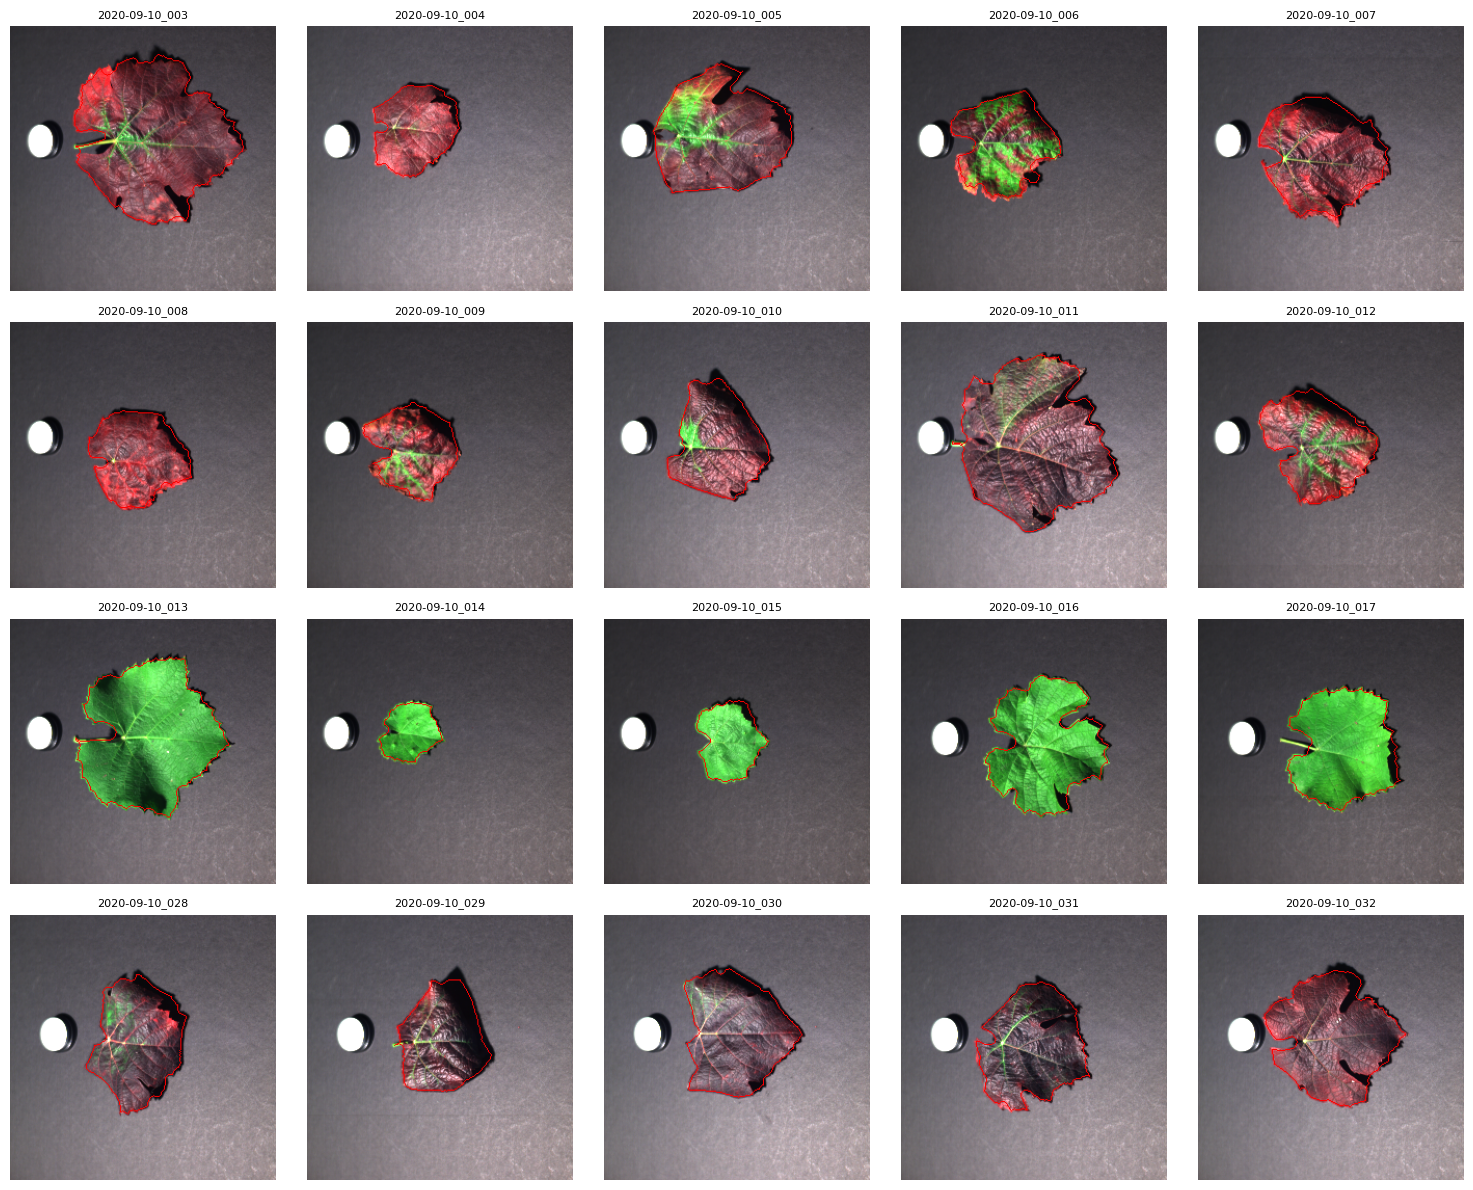

In [9]:
# ===== 2.4 BLIND QC: judge only whether the red outline fits the leaf edge =====
import matplotlib.image as mpimg

ids = sorted(f[:-4] for f in os.listdir(f"{WORK}/qc") if f.endswith(".png"))
PAGE = 0                                   # 0..5 for 120 leaves
chunk = ids[PAGE * 20:(PAGE + 1) * 20]
fig, ax = plt.subplots(int(np.ceil(len(chunk) / 5)), 5, figsize=(15, 3 * int(np.ceil(len(chunk) / 5))), squeeze=False)
for a in ax.ravel(): a.axis("off")
for a, l in zip(ax.ravel(), chunk):
    a.imshow(mpimg.imread(f"{WORK}/qc/{l}.png")); a.set_title(l, fontsize=8)   # IDs only, no labels
plt.tight_layout(); plt.show()

In [10]:
# ===== 2.5 AUDIT + EXCLUSIONS + SAVE X =====
EXCLUDE = {}   # {"2020-09-10_017": "reason"}; only for failed masks or corrupted data, never by label

recs, wl0 = [], None
for l in cohort["directoryName"]:
    p = f"{WORK}/spectra_v2/{l}.npz"
    if not os.path.exists(p):
        continue
    z = np.load(p)
    wl0 = z["wl"] if wl0 is None else wl0
    recs.append(dict(directoryName=l, n_px=int(z["n_px"]), mask_frac=float(z["mask_frac"]), otsu_t=float(z["otsu_t"]),
                     ncomp=int(z["ncomp"]), nonfinite=int(z["nonfinite"]), n_bands=len(z["wl"]),
                     wl_same=bool(z["wl"].shape == wl0.shape and np.allclose(z["wl"], wl0))))
log = pd.DataFrame(recs)
log["flag"] = (log.mask_frac < 0.03) | (log.mask_frac > 0.9) | (log.n_px < 2000) | (~log.wl_same)   # prompts a look, not an exclusion
log["excluded_reason"] = log["directoryName"].map(EXCLUDE)
log.to_csv(f"{WORK}/segmentation_log.csv", index=False)

missing = sorted(set(cohort.directoryName) - set(log.directoryName))
print("processed:", len(log), "/", len(cohort), "| flagged:", int(log.flag.sum()), "| missing:", missing)
print("bands:", log.n_bands.unique(), "| wavelengths identical:", bool(log.wl_same.all()))
display(log[log.flag])

ids = [l for l in log.directoryName if l not in EXCLUDE]
c = cohort.set_index("directoryName").loc[ids]
X = np.vstack([np.load(f"{WORK}/spectra_v2/{l}.npz")["spec"] for l in ids])
print("X:", X.shape, "| NaNs:", int(np.isnan(X).sum()), "| range:", X.min().round(3), "-", X.max().round(3))
print("wavelengths:", wl0.min().round(1), "-", wl0.max().round(1), "nm,", len(wl0), "bands")

np.savez(f"{WORK}/spectra_leaf_mean.npz", X=X, wl=wl0, leaf=np.array(ids), y=c["label"].values,
         variety=c["variety"].values, chl=c["Chl"].values, flav=c["Flav"].values, nbi=c["NBI"].values)

processed: 120 / 120 | flagged: 6 | missing: []
bands: [204] | wavelengths identical: True


,directoryName,n_px,mask_frac,otsu_t,ncomp,nonfinite,n_bands,wl_same,flag,excluded_reason
81,2020-09-11_010,7102,0.027092,0.535184,1,0,204,True,True,NaN
82,2020-09-11_011,6504,0.024811,0.518012,1,0,204,True,True,NaN
86,2020-09-11_015,3229,0.012318,0.529415,1,0,204,True,True,NaN
89,2020-09-11_018,3563,0.013592,0.519902,1,0,204,True,True,NaN
90,2020-09-11_019,4883,0.018627,0.521054,1,0,204,True,True,NaN
91,2020-09-11_020,5093,0.019428,0.494676,1,0,204,True,True,NaN


X: (120, 204) | NaNs: 0 | range: 0.04 - 0.884
wavelengths: 397.3 - 1003.6 nm, 204 bands


phase 3(Exploration)

(120, 204) | FD: 80 | healthy: 40
keeping 198/204 bands: 406-994 nm


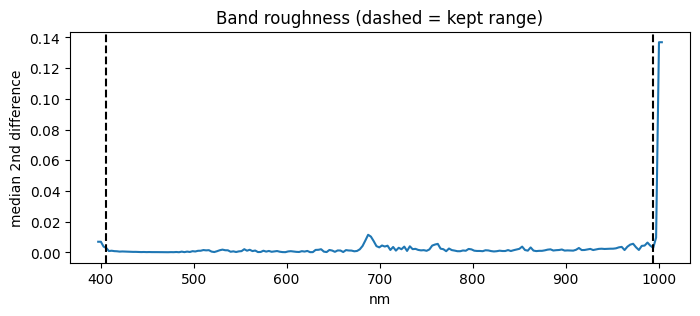

In [11]:
# ===== 3.1 LOAD SPECTRA + LABEL-FREE BAND TRIMMING + PREPROCESSING =====
from scipy.signal import savgol_filter

z = np.load(f"{WORK}/spectra_leaf_mean.npz", allow_pickle=True)   # allow_pickle: variety is an object array
X, wl, leaf_ids, y, variety = z["X"], z["wl"], z["leaf"], z["y"], z["variety"]
chl, flav, nbi = z["chl"], z["flav"], z["nbi"]
print(X.shape, "| FD:", int(y.sum()), "| healthy:", int((y == 0).sum()))

# noise per band from the spectra alone (median 2nd difference); the labels are never used
rough = np.median(np.abs(np.diff(X, n=2, axis=1)), axis=0)
rough = np.r_[rough[0], rough, rough[-1]]                 # pad back to the number of bands

KEEP_NM = None            # e.g. (420, 980) to set the range by hand; None = automatic rule
if KEEP_NM is None:       # trim only the ends where roughness exceeds 3x the median
    ok = rough <= 3 * np.median(rough)
    lo, hi = int(np.argmax(ok)), len(ok) - 1 - int(np.argmax(ok[::-1]))
else:
    lo, hi = int(np.argmin(np.abs(wl - KEEP_NM[0]))), int(np.argmin(np.abs(wl - KEEP_NM[1])))
keep = np.zeros(len(wl), bool); keep[lo:hi + 1] = True
Xt, wlt = X[:, keep], wl[keep]
print(f"keeping {keep.sum()}/{len(wl)} bands: {wlt.min():.0f}-{wlt.max():.0f} nm")

plt.figure(figsize=(8, 3)); plt.plot(wl, rough)
plt.axvline(wlt.min(), c="k", ls="--"); plt.axvline(wlt.max(), c="k", ls="--")
plt.xlabel("nm"); plt.ylabel("median 2nd difference"); plt.title("Band roughness (dashed = kept range)"); plt.show()

# per-leaf operations, so they cannot leak information between train and test leaves
def snv(A):
    return (A - A.mean(1, keepdims=True)) / A.std(1, keepdims=True)    # Eq. 6

def sg(A, window=11, poly=2):
    return savgol_filter(A, window, poly, axis=1)

np.savez(f"{WORK}/spectra_trimmed.npz", Xt=Xt, wlt=wlt, leaf=leaf_ids, y=y, variety=variety, chl=chl, flav=flav, nbi=nbi)

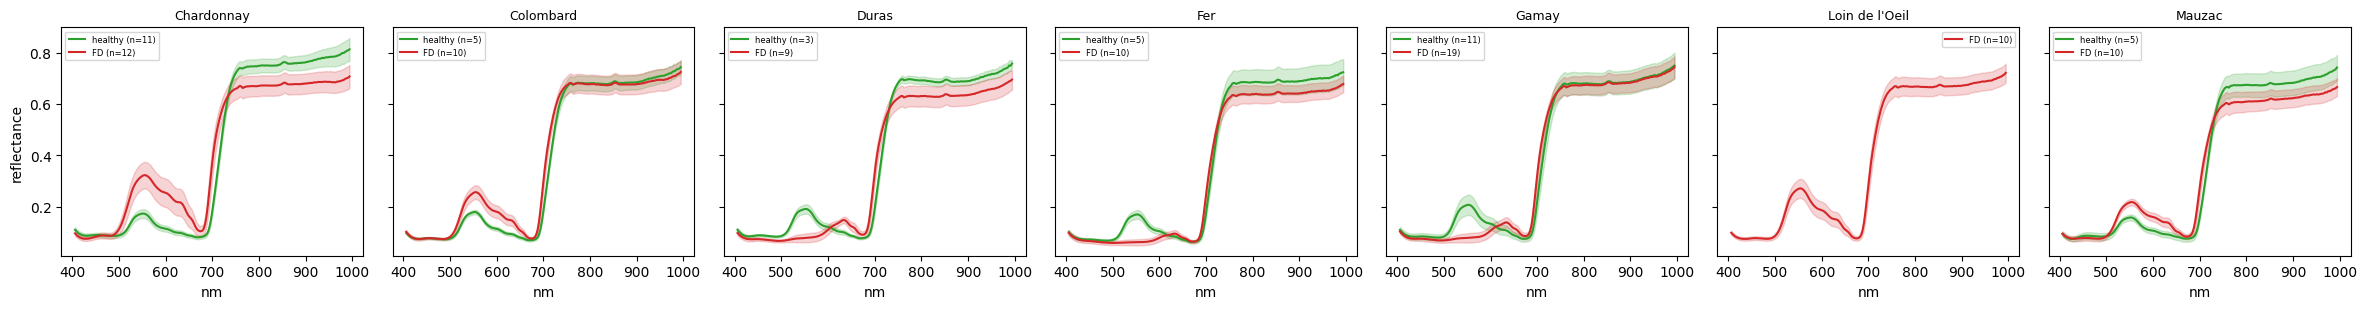

In [12]:
# ===== 3.2 FIGURE 1: MEAN +/- SD SPECTRA PER VARIETY, HEALTHY vs FD =====
vs = sorted(set(variety))
fig, axes = plt.subplots(1, len(vs), figsize=(3.4 * len(vs), 3.2), sharey=True)
for ax, v in zip(axes, vs):
    for lab, col, name in [(0, "tab:green", "healthy"), (1, "tab:red", "FD")]:
        idx = (variety == v) & (y == lab)
        if idx.any():
            mu, sd = Xt[idx].mean(0), Xt[idx].std(0)
            ax.plot(wlt, mu, color=col, label=f"{name} (n={idx.sum()})")
            ax.fill_between(wlt, mu - sd, mu + sd, color=col, alpha=0.2)
    ax.set_title(v, fontsize=9); ax.set_xlabel("nm"); ax.legend(fontsize=6)
axes[0].set_ylabel("reflectance")
plt.tight_layout(); plt.savefig(f"{WORK}/figure1.png", dpi=150); plt.show()

I0000 00:00:1794933613.872343      16 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794933630.522817      16 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


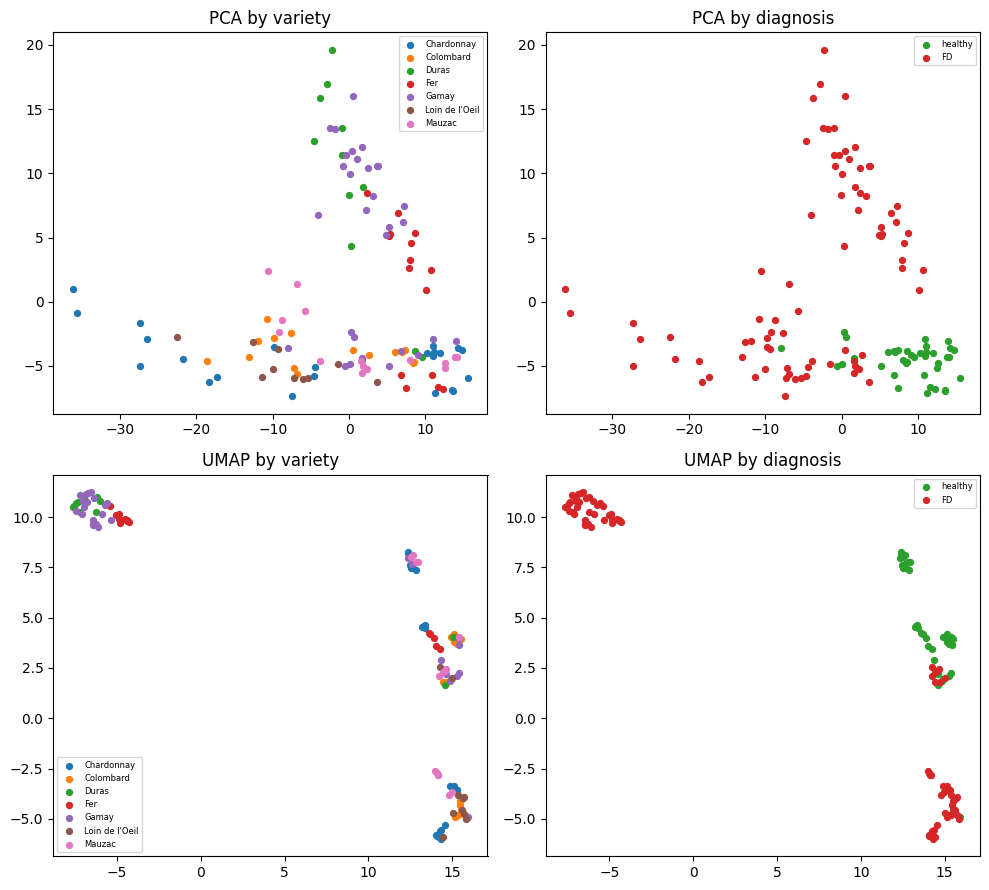

In [13]:
# ===== 3.3 FIGURE 2: PCA/UMAP COLOURED BY VARIETY AND BY DIAGNOSIS =====
# Exploration only: fitted on all leaves, so never quote it as a performance result
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

A = StandardScaler().fit_transform(snv(Xt))
emb = {"PCA": PCA(n_components=2, random_state=SEED).fit_transform(A)}
try:
    import umap
    emb["UMAP"] = umap.UMAP(n_components=2, random_state=SEED, n_neighbors=10).fit_transform(A)
except ImportError:
    print("umap-learn not installed: showing PCA only (%pip install -q umap-learn)")

pal = plt.cm.tab10(np.arange(len(vs)))
fig, axes = plt.subplots(len(emb), 2, figsize=(10, 4.5 * len(emb)), squeeze=False)
for r, (name, P) in enumerate(emb.items()):
    for v, col in zip(vs, pal):
        axes[r, 0].scatter(*P[variety == v].T, color=col, label=v, s=18)
    axes[r, 0].set_title(f"{name} by variety"); axes[r, 0].legend(fontsize=6)
    for lab, col, nm in [(0, "tab:green", "healthy"), (1, "tab:red", "FD")]:
        axes[r, 1].scatter(*P[y == lab].T, color=col, label=nm, s=18)
    axes[r, 1].set_title(f"{name} by diagnosis"); axes[r, 1].legend(fontsize=6)
plt.tight_layout(); plt.savefig(f"{WORK}/figure2.png", dpi=150); plt.show()

In [14]:
# ===== 3.4 CULTIVAR PROBE: can a linear model predict the variety from the spectrum? =====
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
for name, A in {"raw": Xt, "snv": snv(Xt)}.items():
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))   # scaler is refit inside each CV fold
    pred = cross_val_predict(clf, A, variety, cv=skf)
    print(f"{name}: accuracy {accuracy_score(variety, pred):.2f} | balanced {balanced_accuracy_score(variety, pred):.2f}")
print(f"chance {1/len(vs):.2f} | majority-class {pd.Series(variety).value_counts(normalize=True).max():.2f}")
display(pd.crosstab(variety, pred, rownames=["true"], colnames=["predicted (snv)"]))

raw: accuracy 0.73 | balanced 0.71
snv: accuracy 0.74 | balanced 0.74
chance 0.14 | majority-class 0.25


predicted (snv),Chardonnay,Colombard,Duras,Fer,Gamay,Loin de l'Oeil,Mauzac
true,,,,,,,
Chardonnay,19,0,0,0,1,1,2
Colombard,0,9,0,0,4,1,1
Duras,0,1,8,0,3,0,0
Fer,1,0,0,13,1,0,0
Gamay,1,1,6,1,21,0,0
Loin de l'Oeil,0,1,0,0,0,7,2
Mauzac,2,1,0,0,0,0,12


Phase 4: Splits and evaluation framework

In [15]:
# ===== 4.1 OUTER SPLITS: LOCO (cultivars with both classes) + WITHIN-DOMAIN =====
from sklearn.model_selection import RepeatedStratifiedKFold

# Loin de l'Oeil has no healthy leaves: it is never a test fold, but always stays in training
LOCO_EVAL = [v for v in vs if len(set(y[variety == v])) == 2]
print("LOCO test cultivars:", LOCO_EVAL)
loco = {v: (np.where(variety != v)[0], np.where(variety == v)[0]) for v in LOCO_EVAL}

rows = []
for v, (tr, te) in loco.items():
    rows.append(dict(heldout=v, test_n=len(te), test_healthy=int((y[te] == 0).sum()), test_FD=int((y[te] == 1).sum()),
                     train_n=len(tr), train_healthy=int((y[tr] == 0).sum()), train_FD=int((y[tr] == 1).sum())))
fold_table = pd.DataFrame(rows); display(fold_table)
for _, r in fold_table.iterrows():
    if min(r.test_healthy, r.test_FD) < 5:
        print(f"WARNING {r.heldout}: minority class has {min(r.test_healthy, r.test_FD)} test leaves -> noisy per-fold F1")

# within-domain benchmark: random leaf-level splits, stratified by variety AND label
strata = np.array([f"{v}|{l}" for v, l in zip(variety, y)])
assert pd.Series(strata).value_counts().min() >= 3, "smallest stratum is too small for 3 folds"
within = list(RepeatedStratifiedKFold(n_splits=3, n_repeats=5, random_state=SEED).split(Xt, strata))
print("within-domain splits:", len(within))

splits = {"loco": {v: {"train": leaf_ids[tr].tolist(), "test": leaf_ids[te].tolist()} for v, (tr, te) in loco.items()},
          "within": [{"train": leaf_ids[tr].tolist(), "test": leaf_ids[te].tolist()} for tr, te in within],
          "seed": SEED}
json.dump(splits, open(f"{WORK}/splits.json", "w"))   # commit this file for reproducibility

LOCO test cultivars: ['Chardonnay', 'Colombard', 'Duras', 'Fer', 'Gamay', 'Mauzac']


,heldout,test_n,test_healthy,test_FD,train_n,train_healthy,train_FD
0,Chardonnay,23,11,12,97,29,68
1,Colombard,15,5,10,105,35,70
2,Duras,12,3,9,108,37,71
3,Fer,15,5,10,105,35,70
4,Gamay,30,11,19,90,29,61
5,Mauzac,15,5,10,105,35,70


WARNING Duras: minority class has 3 test leaves -> noisy per-fold F1
within-domain splits: 15


In [16]:
# ===== 4.2 INNER SPLITS: hold out one TRAINING cultivar at a time =====
def inner_loco(train_idx):
    """Inner folds for tuning. Cultivars with a single class (Loin de l'Oeil) always stay in inner-train."""
    tv = variety[train_idx]
    folds = []
    for v in sorted(set(tv)):
        va = train_idx[tv == v]
        if len(set(y[va])) < 2:
            continue
        folds.append((train_idx[tv != v], va))
    return folds

for v, (tr, _) in loco.items():
    inner = inner_loco(tr)
    print(f"outer {v}: {len(inner)} inner folds | smallest minority class in an inner val set:",
          min(min((y[va] == 0).sum(), (y[va] == 1).sum()) for _, va in inner))

outer Chardonnay: 5 inner folds | smallest minority class in an inner val set: 3
outer Colombard: 5 inner folds | smallest minority class in an inner val set: 3
outer Duras: 5 inner folds | smallest minority class in an inner val set: 5
outer Fer: 5 inner folds | smallest minority class in an inner val set: 3
outer Gamay: 5 inner folds | smallest minority class in an inner val set: 3
outer Mauzac: 5 inner folds | smallest minority class in an inner val set: 3


In [17]:
# ===== 4.3 METRICS + BOOTSTRAP =====
from sklearn.metrics import (f1_score, balanced_accuracy_score, matthews_corrcoef, roc_auc_score,
                             confusion_matrix, mean_squared_error, mean_absolute_error, r2_score)

def clf_metrics(y_true, y_pred, p_fd=None):
    """Classification metrics; p_fd = predicted probability of FD (needed for AUROC)."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    div = lambda a, b: a / b if b else np.nan
    return dict(macro_f1=f1_score(y_true, y_pred, average="macro", labels=[0, 1], zero_division=0),
                bal_acc=balanced_accuracy_score(y_true, y_pred), mcc=matthews_corrcoef(y_true, y_pred),
                sens=div(tp, tp + fn), spec=div(tn, tn + fp), prec=div(tp, tp + fp),
                auroc=roc_auc_score(y_true, p_fd) if p_fd is not None and len(set(y_true)) == 2 else np.nan)

def ece(y_true, p_fd, bins=10):
    """Expected calibration error on the confidence of the predicted class (Eq. 47)."""
    conf, correct = np.maximum(p_fd, 1 - p_fd), ((p_fd >= 0.5).astype(int) == y_true)
    b = np.digitize(conf, np.linspace(0.5, 1, bins + 1)[1:-1])
    return sum((b == i).mean() * abs(correct[b == i].mean() - conf[b == i].mean()) for i in range(bins) if (b == i).any())

def reg_metrics(t, p):
    return dict(r2=r2_score(t, p), rmse=float(np.sqrt(mean_squared_error(t, p))), mae=mean_absolute_error(t, p))

f1m = lambda t, p: f1_score(t, p, average="macro", labels=[0, 1], zero_division=0)

def bootstrap_ci(metric_fn, y_true, pred, B=2000, seed=SEED):
    """95% percentile CI, resampling leaves. Resamples with one class are skipped."""
    rng, vals = np.random.default_rng(seed), []
    for _ in range(B):
        i = rng.integers(0, len(y_true), len(y_true))
        if len(set(y_true[i])) == 2:
            vals.append(metric_fn(y_true[i], pred[i]))
    return np.percentile(vals, [2.5, 97.5])

def paired_bootstrap_diff(metric_fn, y_true, pred_a, pred_b, B=2000, seed=SEED):
    """Difference a - b on the SAME resampled leaves (Eq. 48). Returns (observed, lo, hi)."""
    rng, d = np.random.default_rng(seed), []
    for _ in range(B):
        i = rng.integers(0, len(y_true), len(y_true))
        if len(set(y_true[i])) == 2:
            d.append(metric_fn(y_true[i], pred_a[i]) - metric_fn(y_true[i], pred_b[i]))
    lo, hi = np.percentile(d, [2.5, 97.5])
    return metric_fn(y_true, pred_a) - metric_fn(y_true, pred_b), lo, hi

# self-test on toy data: should run without errors and give sensible numbers
t, p, pr = np.array([0, 0, 1, 1, 1, 0]), np.array([0, 1, 1, 1, 0, 0]), np.array([.2, .6, .7, .9, .4, .1])
print(clf_metrics(t, p, pr)); print("ECE:", round(ece(t, pr), 3)); print("CI:", bootstrap_ci(f1m, t, p, B=200))

{'macro_f1': 0.6666666666666666, 'bal_acc': np.float64(0.6666666666666666), 'mcc': np.float64(0.3333333333333333), 'sens': np.float64(0.6666666666666666), 'spec': np.float64(0.6666666666666666), 'prec': np.float64(0.6666666666666666), 'auroc': np.float64(0.888888888888889)}
ECE: 0.317
CI: [0.25 1.  ]


In [18]:
# ===== 4.4 LEAKAGE TESTS + SANITY BASELINES =====
from sklearn.dummy import DummyClassifier

# --- structural checks: any failure here means the split code is wrong ---
assert len(set(leaf_ids)) == len(leaf_ids), "duplicate leaves"
for v, (tr, te) in loco.items():
    assert not set(tr) & set(te), f"{v}: train/test overlap"
    assert v not in set(variety[tr]) and set(variety[te]) == {v}, f"{v}: held-out cultivar present in training"
    for itr, iva in inner_loco(tr):
        assert not set(itr) & set(iva) and set(itr) | set(iva) <= set(tr), f"{v}: inner split leaks"
for tr, te in within:
    assert not set(tr) & set(te), "within-domain overlap"
tr0 = next(iter(loco.values()))[0]
A = snv(Xt)
assert not np.allclose(StandardScaler().fit(A[tr0]).mean_, A.mean(0)), "scaler stats equal full-data stats: check the fit rows"
print("structural checks passed")

# --- baselines: pooled out-of-fold predictions over the LOCO test cultivars ---
def run_loco(model_fn, A, y_train=None):
    """Fit on each fold's training leaves, predict the held-out cultivar. Loin de l'Oeil stays at -1 (not tested)."""
    pred, prob = np.full(len(y), -1), np.full(len(y), np.nan)
    for v, (tr, te) in loco.items():
        m = model_fn().fit(A[tr], (y if y_train is None else y_train)[tr])
        prob[te] = m.predict_proba(A[te])[:, 1]; pred[te] = (prob[te] >= 0.5).astype(int)
    return pred, prob

lr = lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced"))
tested = np.concatenate([te for _, te in loco.values()])

p_real, _ = run_loco(lr, A)
p_perm = [run_loco(lr, A, np.random.default_rng(SEED + k).permutation(y))[0] for k in range(5)]
p_maj, _ = run_loco(lambda: DummyClassifier(strategy="most_frequent"), A)

print("LOCO pooled macro-F1")
print("  logistic regression (SNV):", round(f1m(y[tested], p_real[tested]), 3))
print("  shuffled training labels :", round(np.mean([f1m(y[tested], q[tested]) for q in p_perm]), 3), "(should be near 0.5 or below)")
print("  majority class           :", round(f1m(y[tested], p_maj[tested]), 3))

structural checks passed
LOCO pooled macro-F1
  logistic regression (SNV): 0.919
  shuffled training labels : 0.552 (should be near 0.5 or below)
  majority class           : 0.389


Phase 5: Classical baselines

In [19]:
# ===== 5.1 PREPROCESSING VARIANTS + MODEL GRIDS =====
import pickle
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.cross_decomposition import PLSRegression
from sklearn.base import BaseEstimator, ClassifierMixin

PREPS = {"raw": Xt, "sg": sg(Xt), "snv": snv(Xt)}   # per-leaf operations, no train/test leakage
B = Xt.shape[1]

class PLSDA(BaseEstimator, ClassifierMixin):
    """PLS on 0/1 labels. Classes are repeated to equal size so the 0.5 threshold isn't biased by the 2:1 imbalance."""
    def __init__(self, n_components=5):
        self.n_components = n_components
    def fit(self, X, y):
        n = np.bincount(y, minlength=2)
        idx = np.repeat(np.arange(len(y)), np.round(n.max() / n)[y].astype(int))
        self.classes_ = np.array([0, 1])
        self.pls_ = PLSRegression(n_components=min(self.n_components, X.shape[1]), scale=True).fit(X[idx], y[idx])
        return self
    def predict_proba(self, X):
        p = np.clip(self.pls_.predict(X).ravel(), 0, 1)
        return np.c_[1 - p, p]
    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

# name: (constructor, list of hyperparameter dicts). Scalers sit inside the pipelines, so they are fit on training rows only.
MODELS = {
    "PLS-DA": (lambda **k: PLSDA(**k), [dict(n_components=c) for c in (2, 3, 5, 8, 12)]),
    "LinearSVM": (lambda **k: make_pipeline(StandardScaler(), SVC(kernel="linear", probability=True,
                  class_weight="balanced", random_state=SEED, **k)), [dict(C=c) for c in (0.001, 0.01, 0.1, 1)]),
    "RBF-SVM": (lambda C, g: make_pipeline(StandardScaler(), SVC(kernel="rbf", probability=True,
                class_weight="balanced", random_state=SEED, C=C, gamma=g / B)),
                [dict(C=c, g=g) for c in (1, 10, 100) for g in (0.3, 1, 3)]),
    "RandomForest": (lambda **k: RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                     random_state=SEED, n_jobs=-1, **k), [dict(max_depth=d, min_samples_leaf=l) for d in (None, 5) for l in (1, 3)]),
    "LogReg-L2": (lambda **k: make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000,
                  class_weight="balanced", **k)), [dict(C=c) for c in (0.001, 0.01, 0.1, 1)]),
}

In [20]:
# ===== 5.2 TUNE ON INNER FOLDS (training cultivars only) -> EVALUATE ON HELD-OUT CULTIVAR =====
p_fd = lambda m, A: m.predict_proba(A)[:, 1]

results, t0 = {}, time.time()
for prep, A in PREPS.items():
    for name, (make, grid) in MODELS.items():
        prob, picks, inner_best = np.full(len(y), np.nan), [], []
        for v, (tr, te) in loco.items():
            scores = [np.mean([f1m(y[iva], (p_fd(make(**cfg).fit(A[itr], y[itr]), A[iva]) >= 0.5).astype(int))
                               for itr, iva in inner_loco(tr)]) for cfg in grid]
            best = int(np.argmax(scores)); picks.append(best); inner_best.append(scores[best])
            prob[te] = p_fd(make(**grid[best]).fit(A[tr], y[tr]), A[te])   # refit on all outer-train leaves
        pred = (np.nan_to_num(prob) >= 0.5).astype(int)                    # untested leaves stay 0, ignored later
        results[(name, prep)] = dict(prob=prob, pred=pred, picks=picks, inner=float(np.mean(inner_best)))
        print(f"{name:13s}{prep:4s} inner F1 {results[(name, prep)]['inner']:.3f} | LOCO F1 {f1m(y[tested], pred[tested]):.3f} | {time.time()-t0:.0f}s")

pickle.dump(results, open(f"{WORK}/results_classical.pkl", "wb"))

PLS-DA       raw  inner F1 0.936 | LOCO F1 0.940 | 1s
LinearSVM    raw  inner F1 0.895 | LOCO F1 0.836 | 2s
RBF-SVM      raw  inner F1 0.909 | LOCO F1 0.883 | 4s
RandomForest raw  inner F1 0.843 | LOCO F1 0.836 | 134s
LogReg-L2    raw  inner F1 0.886 | LOCO F1 0.840 | 135s
PLS-DA       sg   inner F1 0.921 | LOCO F1 0.912 | 136s
LinearSVM    sg   inner F1 0.897 | LOCO F1 0.836 | 137s
RBF-SVM      sg   inner F1 0.909 | LOCO F1 0.883 | 139s
RandomForest sg   inner F1 0.845 | LOCO F1 0.836 | 269s
LogReg-L2    sg   inner F1 0.886 | LOCO F1 0.840 | 271s
PLS-DA       snv  inner F1 0.955 | LOCO F1 0.909 | 272s
LinearSVM    snv  inner F1 0.943 | LOCO F1 0.930 | 272s
RBF-SVM      snv  inner F1 0.939 | LOCO F1 0.891 | 275s
RandomForest snv  inner F1 0.909 | LOCO F1 0.890 | 411s
LogReg-L2    snv  inner F1 0.935 | LOCO F1 0.911 | 413s


In [21]:
# ===== 5.3 WITHIN-DOMAIN BENCHMARK (random leaf-level splits, same leaves scored as LOCO) =====
for (name, prep), r in results.items():
    make, grid = MODELS[name]; A = PREPS[prep]
    cfg = grid[max(set(r["picks"]), key=r["picks"].count)]     # most frequently selected config across LOCO folds
    f1s = []
    for rep in range(5):                                        # each repeat = 3 consecutive folds covering every leaf once
        pred = np.zeros(len(y), int)
        for tr, te in within[3 * rep: 3 * rep + 3]:
            pred[te] = (p_fd(make(**cfg).fit(A[tr], y[tr]), A[te]) >= 0.5).astype(int)
        f1s.append(f1m(y[tested], pred[tested]))                # Loin de l'Oeil excluded so G compares like with like
    r["within_f1"], r["within_sd"] = float(np.mean(f1s)), float(np.std(f1s))
pickle.dump(results, open(f"{WORK}/results_classical.pkl", "wb"))

In [22]:
# ===== 5.4 SUMMARY: LOCO vs WITHIN-DOMAIN, GAP, PER-CULTIVAR =====
rows = []
for (name, prep), r in results.items():
    m = clf_metrics(y[tested], r["pred"][tested], r["prob"][tested])
    lo, hi = bootstrap_ci(f1m, y[tested], r["pred"][tested])
    rows.append(dict(model=name, prep=prep, inner_f1=r["inner"], within_f1=r["within_f1"], loco_f1=m["macro_f1"],
                     ci_lo=lo, ci_hi=hi, gap=r["within_f1"] - m["macro_f1"], bal_acc=m["bal_acc"], mcc=m["mcc"], auroc=m["auroc"]))
tbl_cls = pd.DataFrame(rows)
display(tbl_cls.round(3)); tbl_cls.to_csv(f"{WORK}/table_classical.csv", index=False)

# choose preprocessing by INNER score (training cultivars), never by the LOCO score
best_prep = {n: max(PREPS, key=lambda p: results[(n, p)]["inner"]) for n in MODELS}
print("preprocessing chosen by inner score:", best_prep)
display(pd.DataFrame({n: {v: f1m(y[te], results[(n, best_prep[n])]["pred"][te]) for v, (_, te) in loco.items()}
                      for n in MODELS}).round(3))

,model,prep,inner_f1,within_f1,loco_f1,ci_lo,ci_hi,gap,bal_acc,mcc,auroc
0,PLS-DA,raw,0.936,0.973,0.940,0.889,0.981,0.033,0.930,0.882,0.988
1,LinearSVM,raw,0.895,0.914,0.836,0.760,0.903,0.079,0.841,0.672,0.932
2,RBF-SVM,raw,0.909,0.945,0.883,0.817,0.941,0.061,0.888,0.767,0.948
3,RandomForest,raw,0.843,0.912,0.836,0.762,0.905,0.076,0.841,0.672,0.938
4,LogReg-L2,raw,0.886,0.934,0.840,0.767,0.906,0.094,0.857,0.691,0.951
5,PLS-DA,sg,0.921,0.967,0.912,0.853,0.962,0.055,0.914,0.824,0.970
6,LinearSVM,sg,0.897,0.951,0.836,0.760,0.903,0.115,0.841,0.672,0.933
7,RBF-SVM,sg,0.909,0.945,0.883,0.817,0.941,0.061,0.888,0.767,0.948
8,RandomForest,sg,0.845,0.910,0.836,0.762,0.905,0.074,0.841,0.672,0.939
9,LogReg-L2,sg,0.886,0.936,0.840,0.767,0.906,0.096,0.857,0.691,0.951


preprocessing chosen by inner score: {'PLS-DA': 'snv', 'LinearSVM': 'snv', 'RBF-SVM': 'snv', 'RandomForest': 'snv', 'LogReg-L2': 'snv'}


,PLS-DA,LinearSVM,RBF-SVM,RandomForest,LogReg-L2
Chardonnay,1.000,1.000,1.000,1.000,1.000
Colombard,0.928,0.928,0.928,0.928,0.928
Duras,1.000,1.000,1.000,0.874,1.000
Fer,0.928,1.000,1.000,1.000,1.000
Gamay,0.689,0.795,0.744,0.744,0.795
Mauzac,1.000,0.928,0.732,0.796,0.796


Phase 6: Neural models

In [23]:
# ===== 6.1 PHYLOSPEC-DG MODEL =====
import torch, torch.nn as nn, torch.nn.functional as F
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

class GRL(torch.autograd.Function):
    """Identity forward; gradient multiplied by -lam backward (Eqs. 26-27)."""
    @staticmethod
    def forward(ctx, x, lam):
        ctx.lam = lam
        return x.view_as(x)
    @staticmethod
    def backward(ctx, grad):
        return -ctx.lam * grad, None

def conv_block(cin, cout, k, p):
    return nn.Sequential(nn.Conv1d(cin, cout, k, padding=k // 2), nn.BatchNorm1d(cout), nn.GELU(), nn.Dropout(p))

class PhyloSpec(nn.Module):
    def __init__(self, n_cult, d=128, p=0.2):
        super().__init__()
        self.enc = nn.Sequential(conv_block(1, 32, 7, p), conv_block(32, 64, 5, p), conv_block(64, d, 3, p),
                                 nn.AdaptiveAvgPool1d(1), nn.Flatten())
        self.stress = nn.Linear(d, 1)
        self.phys = nn.ModuleList([nn.Linear(d, 1) for _ in range(3)])      # Chl, Flav, NBI
        self.disc = nn.Sequential(nn.Linear(d, 64), nn.GELU(), nn.Linear(64, n_cult))
    def forward(self, x, lam=0.0):
        z = self.enc(x.unsqueeze(1))                                         # x: (batch, bands)
        return z, self.stress(z).squeeze(1), torch.cat([h(z) for h in self.phys], 1), self.disc(GRL.apply(z, lam))

device: cpu


In [24]:
# ===== 6.2 TRAINING + PREDICTION =====
PREP_NN = "snv"                         # set from the inner_f1 column in Cell 5.4
A_NN = PREPS[PREP_NN]
PHYS = np.c_[chl, flav, nbi].astype(np.float32)

VARIANTS = {"M0": (False, False), "M1": (True, False), "M2": (False, True), "M3": (True, True)}   # (physiology, adversarial)
NAMES = {"M0": "1D-CNN", "M1": "CNN+Physiology", "M2": "CNN+Cultivar-GRL", "M3": "PhyloSpec-DG"}
DEFAULT_CFG = dict(lr=3e-4, wd=1e-4, dropout=0.2, lam_p=0.25, lam_d=0.1, bs=16)

def train_model(tr, va, cfg, mode, seed, max_epochs=200, patience=20):
    """Fit on leaves `tr`; early-stop on macro-F1 of `va` (a training cultivar, never the test cultivar).
    Normalisation statistics come from `tr` only. Returns (model, stats, best-epoch info)."""
    torch.manual_seed(seed); np.random.seed(seed)
    mu, sd = A_NN[tr].mean(0), A_NN[tr].std(0) + 1e-8          # Eq. 7
    pm, ps = PHYS[tr].mean(0), PHYS[tr].std(0) + 1e-8          # Eq. 20
    cults = sorted(set(variety[tr])); cmap = {c: i for i, c in enumerate(cults)}
    T = lambda a, dt=torch.float32: torch.tensor(a, dtype=dt, device=DEVICE)
    Xtr, Xva = T((A_NN[tr] - mu) / sd), T((A_NN[va] - mu) / sd)
    ytr, ptr = T(y[tr]), T((PHYS[tr] - pm) / ps)
    ctr = T([cmap[c] for c in variety[tr]], torch.long)
    n1 = float(ytr.sum()); n0 = len(tr) - n1
    w1, w0 = len(tr) / (2 * n1), len(tr) / (2 * n0)             # class weights in Eq. 16
    use_phys, use_adv = mode

    model = PhyloSpec(len(cults), p=cfg["dropout"]).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    best, bad = dict(f1=-1, loss=np.inf, state=None, epoch=0), 0
    for ep in range(max_epochs):
        lam = cfg["lam_d"] * (2 / (1 + np.exp(-10 * ep / max_epochs)) - 1) if use_adv else 0.0   # ramp-up avoids unstable early adversarial gradients
        model.train()
        perm = torch.randperm(len(tr), device=DEVICE)
        for i in range(0, len(tr), cfg["bs"]):
            b = perm[i: i + cfg["bs"]]
            if len(b) < 2:
                continue
            z, logit, phys, cl = model(Xtr[b], lam)
            loss = F.binary_cross_entropy_with_logits(logit, ytr[b], weight=torch.where(ytr[b] == 1, w1, w0))
            if use_phys:
                loss = loss + cfg["lam_p"] * sum(F.huber_loss(phys[:, k], ptr[b, k], delta=1.0) for k in range(3))   # Eq. 22
            if use_adv:
                loss = loss + F.cross_entropy(cl, ctr[b])       # the GRL reverses and scales the gradient reaching the encoder
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()

        model.eval()
        with torch.no_grad():
            lg = model(Xva)[1]
            vloss = F.binary_cross_entropy_with_logits(lg, T(y[va])).item()
            vf1 = f1m(y[va], (lg.cpu().numpy() > 0).astype(int))
        if vf1 > best["f1"] or (vf1 == best["f1"] and vloss < best["loss"]):
            best = dict(f1=vf1, loss=vloss, epoch=ep, state={k: t.clone() for k, t in model.state_dict().items()}); bad = 0
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best["state"]); model.eval()
    return model, (mu, sd, pm, ps), best

@torch.no_grad()
def predict(model, stats, idx):
    """Returns (P(FD), physiology in original units, embedding z) for leaves idx."""
    mu, sd, pm, ps = stats
    x = torch.tensor((A_NN[idx] - mu) / sd, dtype=torch.float32, device=DEVICE)
    z, logit, phys, _ = model(x)
    return torch.sigmoid(logit).cpu().numpy(), phys.cpu().numpy() * ps + pm, z.cpu().numpy()

def pick_val_cultivar(tr, seed):
    """Early-stopping cultivar: rotates with the seed among training cultivars that have both classes."""
    ok = sorted(c for c in set(variety[tr]) if len(set(y[variety == c])) == 2)
    return ok[seed % len(ok)]

In [25]:
# ===== 6.3 SMOKE TEST: one LOCO fold, default hyperparameters =====
v, (tr, te) = next(iter(loco.items()))
vc = pick_val_cultivar(tr, 0)
val, trn = tr[variety[tr] == vc], tr[variety[tr] != vc]
for vname, mode in VARIANTS.items():
    t0 = time.time()
    model, stats, best = train_model(trn, val, DEFAULT_CFG, mode, seed=0)
    p, ph, _ = predict(model, stats, te)
    print(f"{vname} | test cultivar {v} | early-stop cultivar {vc} | best epoch {best['epoch']} | val F1 {best['f1']:.3f} "
          f"| test macro-F1 {f1m(y[te], (p >= 0.5).astype(int)):.3f} | {time.time()-t0:.0f}s")

M0 | test cultivar Chardonnay | early-stop cultivar Colombard | best epoch 94 | val F1 1.000 | test macro-F1 1.000 | 19s
M1 | test cultivar Chardonnay | early-stop cultivar Colombard | best epoch 70 | val F1 1.000 | test macro-F1 1.000 | 15s
M2 | test cultivar Chardonnay | early-stop cultivar Colombard | best epoch 61 | val F1 1.000 | test macro-F1 1.000 | 13s
M3 | test cultivar Chardonnay | early-stop cultivar Colombard | best epoch 112 | val F1 1.000 | test macro-F1 1.000 | 22s


Phase 7: Hyperparameter search and final runs

In [26]:
# ===== 7.1 RANDOM SEARCH on inner folds (training cultivars only); resumable =====
SPACE = dict(lr=[1e-5, 3e-5, 1e-4, 3e-4], wd=[1e-5, 1e-4, 1e-3], dropout=[0.1, 0.2, 0.3, 0.4],
             lam_p=[0.05, 0.1, 0.25, 0.5, 1.0], lam_d=[0.01, 0.05, 0.1, 0.25, 0.5], bs=[8, 16, 32])   # Table 3
N_CONFIGS = 8                                    # fixed budget; same configs for every variant and fold
rng = np.random.default_rng(SEED)
CONFIGS = [{k: vals[int(rng.integers(len(vals)))] for k, vals in SPACE.items()} for _ in range(N_CONFIGS)]

SEARCH_FILE = f"{WORK}/nn_search.pkl"
search = pickle.load(open(SEARCH_FILE, "rb")) if os.path.exists(SEARCH_FILE) else {}
t0 = time.time()
for vname, mode in VARIANTS.items():
    for v, (tr, _) in loco.items():
        if (vname, v) in search:
            continue
        search[(vname, v)] = [float(np.mean([train_model(itr, iva, cfg, mode, SEED)[2]["f1"] for itr, iva in inner_loco(tr)]))
                              for cfg in CONFIGS]
        pickle.dump(search, open(SEARCH_FILE, "wb"))
        print(f"{vname} | outer {v} | best inner F1 {max(search[(vname, v)]):.3f} | {time.time()-t0:.0f}s")

chosen = {k: CONFIGS[int(np.argmax(s))] for k, s in search.items()}
json.dump({f"{a}|{b}": c for (a, b), c in chosen.items()}, open(f"{WORK}/nn_chosen_cfg.json", "w"), indent=1)   # Supplementary Table S2

M0 | outer Chardonnay | best inner F1 0.899 | 383s
M0 | outer Colombard | best inner F1 0.915 | 834s
M0 | outer Duras | best inner F1 0.904 | 1357s
M0 | outer Fer | best inner F1 0.938 | 1827s
M0 | outer Gamay | best inner F1 0.952 | 2420s
M0 | outer Mauzac | best inner F1 0.921 | 2904s
M1 | outer Chardonnay | best inner F1 0.901 | 3319s
M1 | outer Colombard | best inner F1 0.915 | 3779s
M1 | outer Duras | best inner F1 0.896 | 4324s
M1 | outer Fer | best inner F1 0.932 | 4762s
M1 | outer Gamay | best inner F1 0.944 | 5441s
M1 | outer Mauzac | best inner F1 0.901 | 5958s
M2 | outer Chardonnay | best inner F1 0.896 | 6337s
M2 | outer Colombard | best inner F1 0.915 | 6791s
M2 | outer Duras | best inner F1 0.904 | 7321s
M2 | outer Fer | best inner F1 0.938 | 7822s
M2 | outer Gamay | best inner F1 0.952 | 8410s
M2 | outer Mauzac | best inner F1 0.921 | 8909s
M3 | outer Chardonnay | best inner F1 0.901 | 9335s
M3 | outer Colombard | best inner F1 0.901 | 9798s
M3 | outer Duras | best inner

In [27]:
# ===== 7.2 FINAL RUNS: chosen config per (variant, held-out cultivar), 5 seeds; resumable =====
SEEDS = [0, 1, 2, 3, 4]
N = len(y)
FINAL_FILE = f"{WORK}/nn_final.pkl"
final = pickle.load(open(FINAL_FILE, "rb")) if os.path.exists(FINAL_FILE) else {}
t0 = time.time()
for vname, mode in VARIANTS.items():
    for v, (tr, te) in loco.items():
        if (vname, v) in final:
            continue
        P, PH, EP = [], [], []
        for seed in SEEDS:
            vc = pick_val_cultivar(tr, seed)
            val, trn = tr[variety[tr] == vc], tr[variety[tr] != vc]
            model, stats, best = train_model(trn, val, chosen[(vname, v)], mode, seed)
            p, ph, _ = predict(model, stats, te)
            P.append(p); PH.append(ph); EP.append(best["epoch"])
            if seed == SEEDS[0]:
                Z = predict(model, stats, np.arange(N))[2]       # embeddings of all leaves, used for the Phase 8 probes
        final[(vname, v)] = dict(te=te, tr=tr, prob=np.array(P), phys=np.array(PH), epochs=EP, z=Z)
        pickle.dump(final, open(FINAL_FILE, "wb"))
        print(f"{vname} | held-out {v} | epochs {EP} | {time.time()-t0:.0f}s")

M0 | held-out Chardonnay | epochs [173, 20, 0, 2, 9] | 67s
M0 | held-out Colombard | epochs [199, 55, 6, 7, 78] | 163s
M0 | held-out Duras | epochs [195, 143, 1, 7, 9] | 235s
M0 | held-out Fer | epochs [127, 190, 70, 8, 14] | 316s
M0 | held-out Gamay | epochs [112, 191, 151, 2, 118] | 417s
M0 | held-out Mauzac | epochs [191, 98, 88, 3, 48] | 530s
M1 | held-out Chardonnay | epochs [198, 78, 11, 10, 47] | 626s
M1 | held-out Colombard | epochs [199, 0, 60, 62, 199] | 720s
M1 | held-out Duras | epochs [199, 199, 67, 78, 106] | 837s
M1 | held-out Fer | epochs [199, 0, 3, 66, 147] | 917s
M1 | held-out Gamay | epochs [112, 190, 150, 2, 102] | 1020s
M1 | held-out Mauzac | epochs [199, 0, 4, 38, 6] | 1078s
M2 | held-out Chardonnay | epochs [0, 0, 26, 89, 186] | 1142s
M2 | held-out Colombard | epochs [199, 0, 60, 101, 199] | 1241s
M2 | held-out Duras | epochs [195, 126, 1, 7, 9] | 1311s
M2 | held-out Fer | epochs [128, 190, 63, 8, 14] | 1390s
M2 | held-out Gamay | epochs [112, 191, 151, 2, 118] 

In [28]:
# ===== 7.3 ASSEMBLE POOLED OUT-OF-FOLD PREDICTIONS =====
oof = {vn: np.full((len(SEEDS), N), np.nan) for vn in VARIANTS}
phys_oof = {vn: np.full((len(SEEDS), N, 3), np.nan) for vn in VARIANTS}
for (vn, v), r in final.items():
    oof[vn][:, r["te"]] = r["prob"]
    phys_oof[vn][:, r["te"], :] = r["phys"]
for vn in VARIANTS:
    per_seed = [f1m(y[tested], (oof[vn][s][tested] >= 0.5).astype(int)) for s in range(len(SEEDS))]
    print(f"{vn} {NAMES[vn]:17s} pooled LOCO macro-F1 per seed: {np.round(per_seed, 3)} | mean {np.mean(per_seed):.3f}")

M0 1D-CNN            pooled LOCO macro-F1 per seed: [0.836 0.853 0.671 0.785 0.834] | mean 0.796
M1 CNN+Physiology    pooled LOCO macro-F1 per seed: [0.793 0.725 0.618 0.802 0.779] | mean 0.744
M2 CNN+Cultivar-GRL  pooled LOCO macro-F1 per seed: [0.732 0.654 0.599 0.785 0.834] | mean 0.721
M3 PhyloSpec-DG      pooled LOCO macro-F1 per seed: [0.793 0.775 0.549 0.802 0.79 ] | mean 0.742


In [29]:
# ===== 7.4 WITHIN-DOMAIN BENCHMARK, NEURAL MODELS (1 seed, 5 repeats x 3 folds) =====
from sklearn.model_selection import train_test_split
within_nn = {}
for vname, mode in VARIANTS.items():
    cfg = json.loads(pd.Series([json.dumps(chosen[(vname, v)], sort_keys=True) for v in loco]).mode()[0])   # most common chosen config
    f1s = []
    for rep in range(5):
        pred = np.zeros(N, int)
        for tr, te in within[3 * rep: 3 * rep + 3]:
            trn, val = train_test_split(tr, test_size=0.2, stratify=strata[tr], random_state=SEED)   # random early-stopping split
            model, stats, _ = train_model(trn, val, cfg, mode, SEED)
            pred[te] = (predict(model, stats, te)[0] >= 0.5).astype(int)
        f1s.append(f1m(y[tested], pred[tested]))
    within_nn[vname] = float(np.mean(f1s))
    print(vname, NAMES[vname], "within-domain macro-F1:", round(within_nn[vname], 3))
json.dump(within_nn, open(f"{WORK}/within_nn.json", "w"))

M0 1D-CNN within-domain macro-F1: 0.856
M1 CNN+Physiology within-domain macro-F1: 0.854
M2 CNN+Cultivar-GRL within-domain macro-F1: 0.854
M3 PhyloSpec-DG within-domain macro-F1: 0.854
